# OE3 · Cuantización INT8 del modelo YOLOv11n-seg

Se elige la mejor semilla de la FASE B, se exporta a ONNX y se cuantiza a INT8 para usarlo en el celular.

## 1) Instalar dependencias
Se instalan versiones fijas de onnx y onnxruntime.

In [1]:
%pip install -q ultralytics==8.4.113 onnx==1.22.0 onnxruntime==1.27.0 onnxslim pycocotools
import ultralytics, onnx, onnxruntime, torch
print("ultralytics", ultralytics.__version__, "| torch", torch.__version__,
      "| onnx", onnx.__version__, "| onnxruntime", onnxruntime.__version__)
assert (ultralytics.__version__, onnx.__version__, onnxruntime.__version__) == ("8.4.113", "1.22.0", "1.27.0"), \
    "Versión distinta: reinicia el entorno y vuelve a ejecutar todo."

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 938.0 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 9.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.1/19.1 MB 49.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.7/18.7 MB 45.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 245.8/245.8 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 1.6 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
ultralytics 8.4.113 | torch 2.11.0+cpu | onnx 1.22.0 | onnxruntime 1.27.0


## 2) Conectar Drive y configuración

In [2]:
import os, json, glob, time, shutil, random, hashlib, platform, datetime
import numpy as np
import cv2
from google.colab import drive
drive.mount("/content/drive")

PROYECTO = "/content/drive/MyDrive/tesis-rg6final"
DATASET = "data_estratificado1"
FASE_B = os.path.join(PROYECTO, "resultados", "oe3", "faseB")
FASE_A = os.path.join(PROYECTO, "resultados", "oe2", "yolov11nseg")
OUT_DIR = os.path.join(PROYECTO, "resultados", "oe3", "ptq_int8")
INFORME = os.path.join(PROYECTO, "informe_para_codex", "oe3")
DATASET_DIR = "/content/datos"
WORK = "/content/trabajo"
SEMILLAS = [42, 123, 2026]

IMGSZ = 1024
CONF = 0.001
CONF_OPERATIVO = 0.25
IOU = 0.70
MAX_DET = 300
N_CALIB, CALIB_SEED = 100, 42
LAT_WARMUP, LAT_RUNS = 10, 100

os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(WORK, exist_ok=True)
if not os.path.exists(DATASET_DIR):
    shutil.copytree(os.path.join(PROYECTO, DATASET), DATASET_DIR)
mb = lambda p: os.path.getsize(p) / 2**20

def sha256(ruta):
    h = hashlib.sha256()
    with open(ruta, "rb") as f:
        for bloque in iter(lambda: f.read(1 << 20), b""):
            h.update(bloque)
    return h.hexdigest()

def cpu_de_colab():
    try:
        with open("/proc/cpuinfo") as f:
            modelo = next((l.split(":", 1)[1].strip() for l in f if l.startswith("model name")), "")
    except Exception:
        modelo = platform.processor()
    return {"node": platform.node(), "cpu_model": modelo, "cpu_count": os.cpu_count(), "python": platform.python_version()}
HOST = cpu_de_colab()
print("CPU:", HOST)

Mounted at /content/drive
CPU: {'node': '2b45813248be', 'cpu_model': 'Intel(R) Xeon(R) CPU @ 2.20GHz', 'cpu_count': 2, 'python': '3.13.16'}


## 3) Elegir la semilla
Se elige la semilla con mayor mAP de máscara en valid.

In [3]:
import pandas as pd

filas = []
for s in SEMILLAS:
    carpeta = os.path.join(FASE_B, f"seed_{s}")
    with open(os.path.join(carpeta, "run_manifest.json")) as f:
        manifiesto = json.load(f)
    with open(os.path.join(carpeta, "reportes", "obj2_results_all_models.json")) as f:
        test = next(r for r in json.load(f) if r.get("phase") == "B")
    filas.append({"seed": s,
                  "valid_map_segm_50_95": round(100 * manifiesto["val_final_valid"]["metrics/mAP50-95(M)"], 2),
                  "test_map_segm_50_95": round(test["map_segm_50_95"], 2), "test_ap50_segm": round(test["ap50_segm"], 2),
                  "test_ap75_segm": round(test["ap75_segm"], 2), "test_map_bbox_50_95": round(test["map_bbox_50_95"], 2),
                  "epocas_ejecutadas": manifiesto["efectivo"].get("epocas_ejecutadas"),
                  "pesos": os.path.join(carpeta, "yolo11nseg_best.pt")})
tabla_b = pd.DataFrame(filas)

valid = dict(zip(tabla_b["seed"], tabla_b["valid_map_segm_50_95"]))
mejor = max(valid, key=valid.get)
SEED_ELEGIDA = 42 if valid[mejor] - valid[42] < 0.1 else mejor
WEIGHTS = tabla_b.loc[tabla_b["seed"] == SEED_ELEGIDA, "pesos"].item()
print(tabla_b.drop(columns="pesos").to_string(index=False))
print(f"\nMejor en valid: semilla {mejor} ({valid[mejor]}) | semilla 42: {valid[42]} → ELEGIDA: {SEED_ELEGIDA}")

fase_a = []
for s in SEMILLAS:
    with open(os.path.join(FASE_A, f"seed_{s}", "reportes", "obj2_results_all_models.json")) as f:
        fase_a.append(next(r for r in json.load(f) if r.get("phase") == "A"))
fase_a = pd.DataFrame(fase_a)
metricas = ["map_segm_50_95", "ap50_segm", "ap75_segm", "map_bbox_50_95"]
comparacion = pd.DataFrame([
    {"fase": "A (OE2, 50 épocas, CommonAug A)",
     **{f"{m}_mean": round(fase_a[m].mean(), 2) for m in metricas}, **{f"{m}_std": round(fase_a[m].std(), 2) for m in metricas}},
    {"fase": "B (OE3, receta optimizada)",
     **{f"{m}_mean": round(tabla_b[f"test_{m}"].mean(), 2) for m in metricas},
     **{f"{m}_std": round(tabla_b[f"test_{m}"].std(), 2) for m in metricas}},
])
print("\nTEST · FASE A vs FASE B (media y desviación de 3 semillas):")
print(comparacion.to_string(index=False))

SRC_SHA256 = sha256(WEIGHTS)
SELECCION = {"regla": "mayor mAP50-95 de mascara en valid; empate (< 0.1 pt frente a la 42) -> 42",
             "valid_map_segm_50_95": {str(k): v for k, v in valid.items()}, "mejor_en_valid": int(mejor),
             "seed_elegida": int(SEED_ELEGIDA), "pesos": WEIGHTS, "sha256": SRC_SHA256}
with open(os.path.join(OUT_DIR, "seleccion_modelo.json"), "w") as f:
    json.dump(SELECCION, f, indent=2, ensure_ascii=False)
tabla_b.to_csv(os.path.join(OUT_DIR, "tabla_faseB.csv"), index=False)
comparacion.to_csv(os.path.join(OUT_DIR, "faseA_vs_faseB.csv"), index=False)

 seed  valid_map_segm_50_95  test_map_segm_50_95  test_ap50_segm  test_ap75_segm  test_map_bbox_50_95  epocas_ejecutadas
   42                 64.89                65.31           97.12           81.07                74.78                200
  123                 65.14                64.85           97.47           79.83                74.85                200
 2026                 65.13                64.68           97.39           78.42                74.92                200

Mejor en valid: semilla 123 (65.14) | semilla 42: 64.89 → ELEGIDA: 123

TEST · FASE A vs FASE B (media y desviación de 3 semillas):
                           fase  map_segm_50_95_mean  ap50_segm_mean  ap75_segm_mean  map_bbox_50_95_mean  map_segm_50_95_std  ap50_segm_std  ap75_segm_std  map_bbox_50_95_std
A (OE2, 50 épocas, CommonAug A)                61.16           95.32           73.75                70.48                0.81           0.79           1.40                0.65
     B (OE3, receta optimizada)

## 4) Imágenes de calibración
Se seleccionan 100 imágenes de train para calibrar la cuantización.

In [4]:
calib_paths = []
for ext in ("*.jpg", "*.jpeg", "*.png"):
    calib_paths += sorted(glob.glob(os.path.join(DATASET_DIR, "train", ext)))
random.Random(CALIB_SEED).shuffle(calib_paths)
calib_paths = sorted(calib_paths[:N_CALIB])
CALIB_SHA256 = hashlib.sha256("\n".join(os.path.basename(p) for p in calib_paths).encode()).hexdigest()
with open(os.path.join(OUT_DIR, "calib_manifest.json"), "w") as f:
    json.dump({"seed": CALIB_SEED, "n": len(calib_paths), "files": [os.path.basename(p) for p in calib_paths]}, f, indent=1)
print(f"Calibración: {len(calib_paths)} fotos de train (semilla {CALIB_SEED}) | sha256 {CALIB_SHA256[:16]}")

Calibración: 100 fotos de train (semilla 42) | sha256 dca4ed2a766d07d0


## 5) Exportar a ONNX FP32
Se exporta el modelo a ONNX con entrada dinámica.

In [5]:
from ultralytics import YOLO

FP32_ONNX = os.path.join(OUT_DIR, "yolo11nseg_fp32_dyn.onnx")
INT8_ONNX = os.path.join(OUT_DIR, "yolo11nseg_int8_conv_only_dyn.onnx")
ORIGEN_MODELOS = os.path.join(OUT_DIR, "origen_modelos.json")
huella = {"seed": SEED_ELEGIDA, "pesos_sha256": SRC_SHA256, "calib_sha256": CALIB_SHA256,
          "imgsz": IMGSZ, "opset": 13, "receta": "conv_only"}
previo = json.load(open(ORIGEN_MODELOS)) if os.path.exists(ORIGEN_MODELOS) else {}
REUTILIZAR = (previo.get("huella") == huella and os.path.exists(FP32_ONNX) and os.path.exists(INT8_ONNX)
              and previo.get("fp32_sha256") == sha256(FP32_ONNX) and previo.get("int8_sha256") == sha256(INT8_ONNX))

PT_LOCAL = os.path.join(WORK, "yolo11nseg_best.pt")
shutil.copy2(WEIGHTS, PT_LOCAL)
if REUTILIZAR:
    print("Los ONNX ya existen con la misma huella: no se repiten la exportación ni la cuantización.")
else:
    exportado = YOLO(PT_LOCAL).export(format="onnx", imgsz=IMGSZ, opset=13, simplify=True, dynamic=True,
                                      batch=1, device="cpu")
    shutil.copy2(str(exportado), FP32_ONNX)
    print(f"ONNX FP32: {FP32_ONNX} ({mb(FP32_ONNX):.1f} MB)")
m = onnx.load(FP32_ONNX)
print("salidas:", [(o.name, [d.dim_value or d.dim_param for d in o.type.tensor_type.shape.dim]) for o in m.graph.output])

Ultralytics 8.4.113 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino/
YOLO11n-seg summary (fused): 114 layers, 2,834,958 parameters, 0 gradients, 24.9 GFLOPs

PyTorch: starting from '/content/trabajo/yolo11nseg_best.pt' with input shape (1, 3, 1024, 1024) BCHW and output shape(s) ((1, 38, 21504), (1, 32, 256, 256)) (5.8 MB)

ONNX: starting export with onnx 1.22.0 opset 13...
ONNX: slimming with onnxslim 0.1.98...
ONNX: export success ✅ 11.3s, saved as '/content/trabajo/yolo11nseg_best.onnx' (11.5 MB)

Export complete (19.1s)
Results saved to /content/trabajo/yolo11nseg_best.onnx
Predict:         yolo predict task=segment model=/content/trabajo/yolo11nseg_best.onnx imgsz=1024 
Validate:        yolo val task=segment model=/content/trabajo/yolo11nseg_best.onnx imgsz=1024 data=/content/yolo/dataset/dataset.yaml  
Visualize:       https

## 6) Cuantización INT8
Se cuantizan las capas convolucionales a 8 bits, excluyendo las más sensibles.

In [6]:
from collections import Counter
from onnxruntime.quantization import (quantize_static, QuantType, QuantFormat, CalibrationDataReader,
                                      CalibrationMethod)
from onnxruntime.quantization.shape_inference import quant_pre_process

def letterbox114(img, size):
    h, w = img.shape[:2]
    r = min(size / h, size / w)
    nh, nw = int(round(h * r)), int(round(w * r))
    if (nw, nh) != (w, h):
        img = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_LINEAR)
    dw, dh = (size - nw) / 2, (size - nh) / 2
    top, bottom = int(round(dh - 0.1)), int(round(dh + 0.1))
    left, right = int(round(dw - 0.1)), int(round(dw + 0.1))
    return cv2.copyMakeBorder(img, top, bottom, left, right, cv2.BORDER_CONSTANT, value=(114, 114, 114))

def preprocesar(ruta, size):
    img = cv2.imread(ruta, cv2.IMREAD_COLOR)
    if img is None:
        return None
    img = cv2.cvtColor(letterbox114(img, size), cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
    return np.ascontiguousarray(img.transpose(2, 0, 1))[None]

def capas_excluidas(ruta_onnx, nc):
    m = onnx.load(ruta_onnx)
    forma = {i.name: list(i.dims) for i in m.graph.initializer}
    excluir = set()
    for n in m.graph.node:
        if n.op_type == "Conv" and len(n.input) > 1 and n.input[1] in forma:
            d = forma[n.input[1]]
            if len(d) == 4 and d[0] == 1 and d[2] == 1 and d[3] == 1 and d[1] <= 32:
                excluir.add(n.name)
            if d[0] == nc:
                excluir.add(n.name)
    return sorted(x for x in excluir if x)

class LectorCalibracion(CalibrationDataReader):
    def __init__(self, ruta_onnx, rutas):
        sesion = onnxruntime.InferenceSession(ruta_onnx, providers=["CPUExecutionProvider"])
        self.nombre, self.rutas, self.i = sesion.get_inputs()[0].name, rutas, 0
    def get_next(self):
        while self.i < len(self.rutas):
            arr = preprocesar(self.rutas[self.i], IMGSZ)
            self.i += 1
            if arr is not None:
                return {self.nombre: arr}
        return None
    def rewind(self):
        self.i = 0

with open(os.path.join(DATASET_DIR, "train", "_annotations.coco.json")) as f:
    NC = len(json.load(f)["categories"])

if REUTILIZAR:
    EXCLUIDAS, PREP_ESTADO = previo["excluidas"], previo["prep_estado"]
else:
    prep = os.path.join(WORK, "yolo11nseg_fp32_prep.onnx")
    try:
        quant_pre_process(FP32_ONNX, prep)
        PREP_ESTADO = "ok"
    except Exception:
        try:
            quant_pre_process(FP32_ONNX, prep, skip_symbolic_shape=True)
            PREP_ESTADO = "ok_skip_symbolic_shape"
        except Exception as e:
            print("quant_pre_process falló (sigo con el FP32 sin preparar):", str(e)[:200])
            prep, PREP_ESTADO = FP32_ONNX, "fallback_fp32_crudo"
    print("quant_pre_process:", PREP_ESTADO)
    EXCLUIDAS = capas_excluidas(prep, NC)
    print(f"nc={NC} | capas excluidas ({len(EXCLUIDAS)}):", *EXCLUIDAS, sep="\n   - ")
    t0 = time.time()
    quantize_static(prep, INT8_ONNX, LectorCalibracion(prep, calib_paths),
                    quant_format=QuantFormat.QDQ, per_channel=True,
                    weight_type=QuantType.QInt8, activation_type=QuantType.QInt8,
                    calibrate_method=CalibrationMethod.MinMax,
                    extra_options={"ActivationSymmetric": False},
                    nodes_to_exclude=EXCLUIDAS, op_types_to_quantize=["Conv"])
    print(f"INT8 listo en {time.time() - t0:.0f} s")
    with open(ORIGEN_MODELOS, "w") as f:
        json.dump({"huella": huella, "fp32_sha256": sha256(FP32_ONNX), "int8_sha256": sha256(INT8_ONNX),
                   "excluidas": EXCLUIDAS, "prep_estado": PREP_ESTADO}, f, indent=2)

operadores = Counter(n.op_type for n in onnx.load(INT8_ONNX).graph.node)
nodos_qdq = operadores["QuantizeLinear"] + operadores["DequantizeLinear"]
assert nodos_qdq > 0, "El modelo no tiene nodos Quantize/Dequantize: no es INT8."
COBERTURA = {"file": os.path.basename(INT8_ONNX), "q_dq_nodes": int(nodos_qdq),
             "conv_like_nodes": int(operadores["Conv"] + operadores["ConvTranspose"] + operadores["Gemm"]),
             "operators": dict(operadores), "nodos_excluidos": EXCLUIDAS,
             "classification": "QDQ / PTQ selectiva (precision mixta)"}
with open(os.path.join(OUT_DIR, "quantization_coverage.json"), "w") as f:
    json.dump(COBERTURA, f, indent=2)
print(f"FP32 = {mb(FP32_ONNX):.1f} MB | INT8 = {mb(INT8_ONNX):.1f} MB | compresión = {mb(FP32_ONNX) / mb(INT8_ONNX):.2f}x"
      f" | {nodos_qdq} nodos Q/DQ")

quant_pre_process: ok_skip_symbolic_shape
nc=2 | capas excluidas (4):
   - /model.23/cv3.0/cv3.0.2/Conv
   - /model.23/cv3.1/cv3.1.2/Conv
   - /model.23/cv3.2/cv3.2.2/Conv
   - /model.23/dfl/conv/Conv
INT8 listo en 108 s
FP32 = 11.5 MB | INT8 = 3.7 MB | compresión = 3.09x | 552 nodos Q/DQ


## 7) Prueba rápida FP32 frente a INT8
Se comprueba en tres imágenes que el modelo INT8 siga detectando.

In [7]:
def entrada_rect(img):
    h, w = img.shape[:2]
    return (768, 1024) if w >= h else (1024, 768)

def vistazo(ruta_modelo, img):
    r = YOLO(ruta_modelo, task="segment").predict(img, imgsz=entrada_rect(img), conf=0.001, iou=IOU,
                                                  max_det=MAX_DET, device="cpu", verbose=False)[0]
    n = 0 if r.boxes is None else len(r.boxes)
    return n, (float(r.boxes.conf.max()) if n else 0.0)

todo_bien = True
for ruta in sorted(glob.glob(os.path.join(DATASET_DIR, "valid", "*.jpg")))[:3]:
    img = cv2.imread(ruta)
    nf, cf = vistazo(FP32_ONNX, img)
    ni, ci = vistazo(INT8_ONNX, img)
    ok = ni > 0 and ci >= 0.5 * cf
    todo_bien &= ok
    print(f"[{'OK ' if ok else 'MAL'}] {os.path.basename(ruta)[:38]:40s} FP32: {nf:3d} det, conf máx {cf:.2f} | "
          f"INT8: {ni:3d} det, conf máx {ci:.2f}")
print("\nVEREDICTO:", "INT8 sano → evaluación completa" if todo_bien else "INT8 degradado: revisa la cuantización")

Loading /content/drive/MyDrive/tesis-rg6final/resultados/oe3/ptq_int8/yolo11nseg_fp32_dyn.onnx for ONNX Runtime inference...
Using ONNX Runtime 1.27.0 with CPUExecutionProvider
Loading /content/drive/MyDrive/tesis-rg6final/resultados/oe3/ptq_int8/yolo11nseg_int8_conv_only_dyn.onnx for ONNX Runtime inference...
Using ONNX Runtime 1.27.0 with CPUExecutionProvider
[OK ] IMG_20261011_171109_jpg.rf.76e27df32f3   FP32:  11 det, conf máx 0.93 | INT8:   4 det, conf máx 0.94
Loading /content/drive/MyDrive/tesis-rg6final/resultados/oe3/ptq_int8/yolo11nseg_fp32_dyn.onnx for ONNX Runtime inference...
Using ONNX Runtime 1.27.0 with CPUExecutionProvider
Loading /content/drive/MyDrive/tesis-rg6final/resultados/oe3/ptq_int8/yolo11nseg_int8_conv_only_dyn.onnx for ONNX Runtime inference...
Using ONNX Runtime 1.27.0 with CPUExecutionProvider
[OK ] IMG_20261011_171311_jpg.rf.cc230e332ed   FP32:  21 det, conf máx 0.94 | INT8:  15 det, conf máx 0.94
Loading /content/drive/MyDrive/tesis-rg6final/resultados/o

## 8) Evaluación en test
Se evalúan los modelos FP32 e INT8 con COCOeval.

In [8]:
import io, contextlib
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
import pycocotools.mask as mask_util

TEST_DIR = os.path.join(DATASET_DIR, "test")
with contextlib.redirect_stdout(io.StringIO()):
    coco_gt = COCO(os.path.join(TEST_DIR, "_annotations.coco.json"))
cats = sorted(coco_gt.loadCats(coco_gt.getCatIds()), key=lambda c: c["id"])
IDX2CATID = {i: c["id"] for i, c in enumerate(cats)}
NOMBRES = [c["name"] for c in cats]
assert list(YOLO(PT_LOCAL).names.values()) == NOMBRES, "Las clases del modelo no coinciden con las del test"
img_ids = sorted(coco_gt.getImgIds())

def evaluar(ruta_modelo, tag):
    modelo = YOLO(ruta_modelo, task="segment")
    resultados = []
    t0 = time.time()
    for j, img_id in enumerate(img_ids):
        info = coco_gt.loadImgs(img_id)[0]
        img = cv2.imread(os.path.join(TEST_DIR, info["file_name"]), cv2.IMREAD_COLOR)
        r = modelo.predict(img, imgsz=entrada_rect(img), conf=CONF, iou=IOU, max_det=MAX_DET,
                           retina_masks=True, device="cpu", verbose=False)[0]
        n = 0 if r.boxes is None else len(r.boxes)
        if n > 0:
            cajas = r.boxes.xyxy.cpu().numpy()
            confs = r.boxes.conf.cpu().numpy()
            clases = r.boxes.cls.cpu().numpy().astype(int)
            mascaras = r.masks.data.cpu().numpy().astype(np.uint8)
            for i in range(n):
                x1, y1, x2, y2 = cajas[i].tolist()
                rle = mask_util.encode(np.asfortranarray(mascaras[i]))
                rle["counts"] = rle["counts"].decode("utf-8")
                resultados.append({"image_id": int(img_id), "category_id": int(IDX2CATID[int(clases[i])]),
                                   "bbox": [x1, y1, x2 - x1, y2 - y1], "score": float(confs[i]), "segmentation": rle})
        if (j + 1) % 20 == 0 or j + 1 == len(img_ids):
            print(f"  [{tag}] {j + 1}/{len(img_ids)} fotos ({time.time() - t0:.0f} s)", flush=True)
    with open(os.path.join(OUT_DIR, f"predicciones_{tag}.json"), "w") as f:
        json.dump(resultados, f)
    fila = {"tag": tag, "model_key": "yolo11nseg", "arch": "YOLOv11n-seg", "file_mb": round(mb(ruta_modelo), 2),
            "n_eval": len(img_ids), "artifact_sha256": sha256(ruta_modelo)}
    with contextlib.redirect_stdout(io.StringIO()):
        dets = coco_gt.loadRes(resultados)
    for tipo in ("bbox", "segm"):
        ev = COCOeval(coco_gt, dets, tipo)
        with contextlib.redirect_stdout(io.StringIO()):
            ev.evaluate(); ev.accumulate(); ev.summarize()
        fila[f"map_{tipo}"] = round(float(ev.stats[0]) * 100, 2)
        fila[f"map50_{tipo}"] = round(float(ev.stats[1]) * 100, 2)
        fila[f"map75_{tipo}"] = round(float(ev.stats[2]) * 100, 2)
    print(f"[{tag}] mAP máscara {fila['map_segm']} | mAP caja {fila['map_bbox']}")
    return fila

PLAN = [("yolo_fp32_onnx_rect", FP32_ONNX), ("yolo_int8_onnx_conv_only_rect", INT8_ONNX)]
FILAS = [evaluar(ruta, tag) for tag, ruta in PLAN]

Loading /content/drive/MyDrive/tesis-rg6final/resultados/oe3/ptq_int8/yolo11nseg_fp32_dyn.onnx for ONNX Runtime inference...
Using ONNX Runtime 1.27.0 with CPUExecutionProvider
  [yolo_fp32_onnx_rect] 20/141 fotos (27 s)
  [yolo_fp32_onnx_rect] 40/141 fotos (50 s)
  [yolo_fp32_onnx_rect] 60/141 fotos (79 s)
  [yolo_fp32_onnx_rect] 80/141 fotos (98 s)
  [yolo_fp32_onnx_rect] 100/141 fotos (123 s)
  [yolo_fp32_onnx_rect] 120/141 fotos (145 s)
  [yolo_fp32_onnx_rect] 140/141 fotos (172 s)
  [yolo_fp32_onnx_rect] 141/141 fotos (174 s)
[yolo_fp32_onnx_rect] mAP máscara 64.25 | mAP caja 75.0
Loading /content/drive/MyDrive/tesis-rg6final/resultados/oe3/ptq_int8/yolo11nseg_int8_conv_only_dyn.onnx for ONNX Runtime inference...
Using ONNX Runtime 1.27.0 with CPUExecutionProvider
  [yolo_int8_onnx_conv_only_rect] 20/141 fotos (29 s)
  [yolo_int8_onnx_conv_only_rect] 40/141 fotos (54 s)
  [yolo_int8_onnx_conv_only_rect] 60/141 fotos (88 s)
  [yolo_int8_onnx_conv_only_rect] 80/141 fotos (113 s)
  [

## 9) Latencia en CPU
Se mide la latencia de ambos modelos en la CPU de Colab como referencia.

In [9]:
def pasada_latencia(ruta_modelo, conf):
    modelo = YOLO(ruta_modelo, task="segment")
    args = dict(conf=conf, iou=IOU, max_det=MAX_DET, retina_masks=True, device="cpu", verbose=False)
    ids = img_ids[:LAT_RUNS]
    img0 = cv2.imread(os.path.join(TEST_DIR, coco_gt.loadImgs(ids[0])[0]["file_name"]))
    for _ in range(LAT_WARMUP):
        modelo.predict(img0, imgsz=entrada_rect(img0), **args)
    tiempos = []
    for i in ids:
        img = cv2.imread(os.path.join(TEST_DIR, coco_gt.loadImgs(i)[0]["file_name"]), cv2.IMREAD_COLOR)
        t0 = time.perf_counter()
        modelo.predict(img, imgsz=entrada_rect(img), **args)
        tiempos.append((time.perf_counter() - t0) * 1000.0)
    return tiempos

print(f"Latencia: {LAT_WARMUP} de calentamiento + {LAT_RUNS} fotos | {HOST['cpu_model']} x{HOST['cpu_count']}")
for fila, (tag, ruta) in zip(FILAS, PLAN):
    for prefijo, conf in (("lat_e2e_ms", CONF), ("lat_op_ms", CONF_OPERATIVO)):
        t = pasada_latencia(ruta, conf)
        fila.update({f"{prefijo}_p50": round(float(np.percentile(t, 50)), 1),
                     f"{prefijo}_p95": round(float(np.percentile(t, 95)), 1),
                     f"{prefijo}_mean": round(float(np.mean(t)), 1)})
        print(f"  [{tag}] conf={conf}: p50={fila[prefijo + '_p50']} ms | p95={fila[prefijo + '_p95']} ms")
    fila.update({"lat_runs": LAT_RUNS, "lat_warmup": LAT_WARMUP, "lat_host": HOST["node"],
                 "lat_cpu": HOST["cpu_model"], "lat_cpu_count": HOST["cpu_count"]})

fp32, int8 = FILAS
int8["delta_map_segm_vs_fp32onnx"] = round(int8["map_segm"] - fp32["map_segm"], 2)
int8["delta_map_bbox_vs_fp32onnx"] = round(int8["map_bbox"] - fp32["map_bbox"], 2)
int8["retencion_segm_pct"] = round(100.0 * int8["map_segm"] / fp32["map_segm"], 1) if fp32["map_segm"] else None
int8["retencion_bbox_pct"] = round(100.0 * int8["map_bbox"] / fp32["map_bbox"], 1) if fp32["map_bbox"] else None
int8["speedup_cpu_vs_fp32onnx"] = round(fp32["lat_e2e_ms_p50"] / int8["lat_e2e_ms_p50"], 2)
int8["speedup_op_cpu_vs_fp32onnx"] = round(fp32["lat_op_ms_p50"] / int8["lat_op_ms_p50"], 2)
if int8["speedup_op_cpu_vs_fp32onnx"] < 1.15:
    int8["nota_speedup_cpu"] = ("~1x o menos esperado en x86 de Colab (sin VNNI, overhead QDQ); "
                                "la aceleración INT8 se mide en ARM (teléfono).")
int8["compression_x_vs_fp32onnx"] = round(fp32["file_mb"] / int8["file_mb"], 2)

df = pd.DataFrame(FILAS)
print(); print(df.to_string(index=False))
with open(os.path.join(OUT_DIR, "obj3_yolo_rect_results.json"), "w") as f:
    json.dump(FILAS, f, indent=2, ensure_ascii=False)
df.to_csv(os.path.join(OUT_DIR, "obj3_yolo_rect_results.csv"), index=False)

import importlib.metadata as metadata
def version(paquete):
    try:
        return metadata.version(paquete)
    except Exception:
        return None
with open(os.path.join(OUT_DIR, "run_manifest.json"), "w") as f:
    json.dump({"arch": "YOLOv11n-seg", "fecha_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(),
               "host": HOST, "seleccion": SELECCION,
               "versiones": {p: version(p) for p in ("ultralytics", "torch", "onnx", "onnxruntime", "onnxslim",
                                                     "numpy", "opencv-python", "opencv-python-headless", "pycocotools")},
               "cuantizacion": {"formato": "QDQ", "per_channel": True, "pesos": "QInt8", "activaciones": "QInt8",
                                "calibracion": "MinMax", "activation_symmetric": False, "op_types": ["Conv"],
                                "excluidas": EXCLUIDAS, "prep_estado": PREP_ESTADO, "n_calib": len(calib_paths),
                                "calib_seed": CALIB_SEED, "calib_sha256": CALIB_SHA256, "imgsz_calib": IMGSZ},
               "evaluacion": {"conf": CONF, "iou": IOU, "max_det": MAX_DET, "entrada": "rectangular 768x1024 / 1024x768",
                              "n_test": len(img_ids)},
               "latencia": {"definicion": "predict() extremo a extremo (preproceso + inferencia + post-proceso + "
                                          "mascaras), batch 1, CPU, entrada rectangular, lectura de imagen fuera del cronometro",
                            "conf_protocolo": CONF, "conf_operativo": CONF_OPERATIVO,
                            "warmup": LAT_WARMUP, "runs": LAT_RUNS},
               "artefactos": {tag: {"path": ruta, "sha256": sha256(ruta)} for tag, ruta in PLAN}},
              f, indent=2, ensure_ascii=False, default=str)
print("Guardado: obj3_yolo_rect_results.json/.csv y run_manifest.json en", OUT_DIR)

Latencia: 10 de calentamiento + 100 fotos | Intel(R) Xeon(R) CPU @ 2.20GHz x2
Loading /content/drive/MyDrive/tesis-rg6final/resultados/oe3/ptq_int8/yolo11nseg_fp32_dyn.onnx for ONNX Runtime inference...
Using ONNX Runtime 1.27.0 with CPUExecutionProvider
  [yolo_fp32_onnx_rect] conf=0.001: p50=801.2 ms | p95=3330.5 ms
Loading /content/drive/MyDrive/tesis-rg6final/resultados/oe3/ptq_int8/yolo11nseg_fp32_dyn.onnx for ONNX Runtime inference...
Using ONNX Runtime 1.27.0 with CPUExecutionProvider
  [yolo_fp32_onnx_rect] conf=0.25: p50=540.5 ms | p95=1111.5 ms
Loading /content/drive/MyDrive/tesis-rg6final/resultados/oe3/ptq_int8/yolo11nseg_int8_conv_only_dyn.onnx for ONNX Runtime inference...
Using ONNX Runtime 1.27.0 with CPUExecutionProvider
  [yolo_int8_onnx_conv_only_rect] conf=0.001: p50=1024.5 ms | p95=2922.1 ms
Loading /content/drive/MyDrive/tesis-rg6final/resultados/oe3/ptq_int8/yolo11nseg_int8_conv_only_dyn.onnx for ONNX Runtime inference...
Using ONNX Runtime 1.27.0 with CPUExecuti

## 10) Figura
Se comparan precisión, tamaño y latencia de FP32 e INT8.

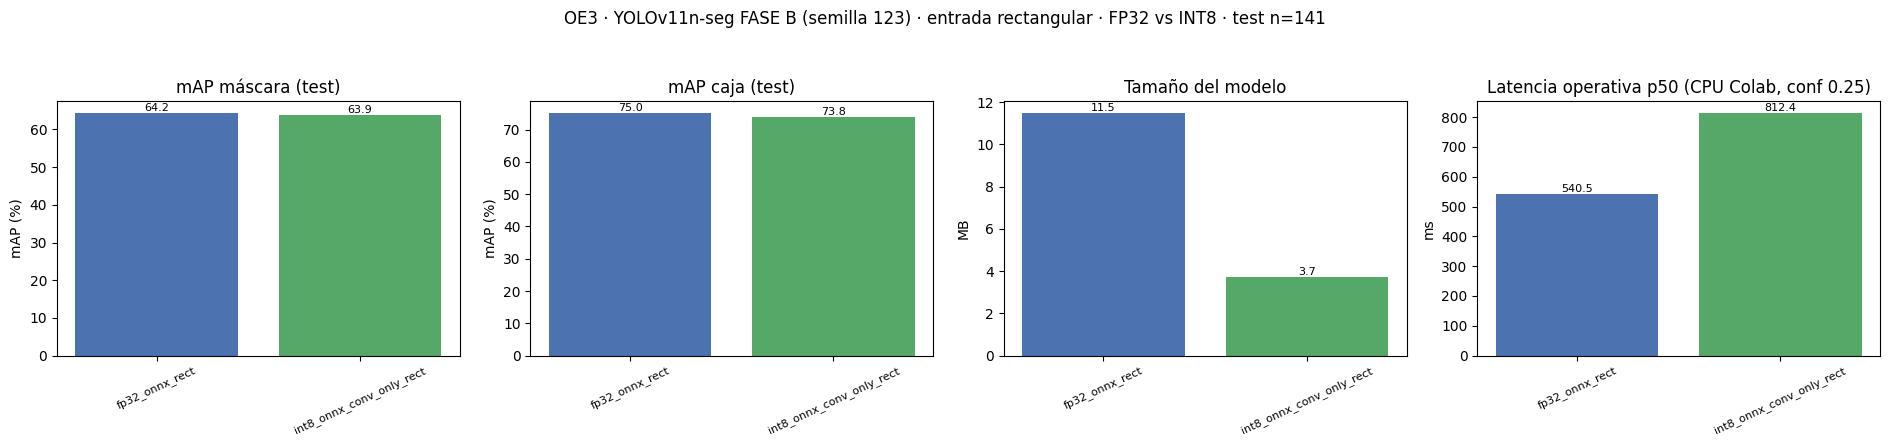

In [10]:
import matplotlib.pyplot as plt
etiquetas = [f["tag"].replace("yolo_", "") for f in FILAS]
paneles = [([f["map_segm"] for f in FILAS], "mAP máscara (test)", "mAP (%)"),
           ([f["map_bbox"] for f in FILAS], "mAP caja (test)", "mAP (%)"),
           ([f["file_mb"] for f in FILAS], "Tamaño del modelo", "MB"),
           ([f["lat_op_ms_p50"] for f in FILAS], "Latencia operativa p50 (CPU Colab, conf 0.25)", "ms")]
fig, axs = plt.subplots(1, 4, figsize=(19, 4.2))
for ax, (valores, titulo, unidad) in zip(axs, paneles):
    barras = ax.bar(etiquetas, valores, color=["#4C72B0", "#55A868"])
    ax.set_title(titulo); ax.set_ylabel(unidad)
    for b, v in zip(barras, valores):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{v:.1f}", ha="center", va="bottom", fontsize=8)
    ax.tick_params(axis="x", rotation=25, labelsize=8)
fig.suptitle(f"OE3 · YOLOv11n-seg FASE B (semilla {SEED_ELEGIDA}) · entrada rectangular · FP32 vs INT8 · test n={len(img_ids)}",
             y=1.05)
fig.tight_layout()
FIGURA = os.path.join(OUT_DIR, "obj3_yolo_rect_fp32_vs_int8.png")
fig.savefig(FIGURA, dpi=200, bbox_inches="tight")
plt.show()

## 11) Archivo de clases para las apps
Se genera classes.json con las clases, el preprocesado y los umbrales por clase.

In [11]:
with open(os.path.join(FASE_B, f"seed_{SEED_ELEGIDA}", "reportes", "umbral_operativo_f1_valid.json")) as f:
    UMBRAL_F1 = json.load(f)["por_clase"]
classes_json = {
    "model": f"YOLOv11n-seg (Ultralytics 8.4.113) · FASE B · semilla {SEED_ELEGIDA}",
    "names": NOMBRES,
    "idx_to_category_id": {str(k): int(v) for k, v in IDX2CATID.items()},
    "imgsz": IMGSZ,
    "entrada": "dinamica; app vertical 1x3x1024x768 (N,C,alto,ancho); evaluacion 768x1024 o 1024x768 segun orientacion",
    "preprocess": {"letterbox_pad": 114, "color": "RGB", "scale": "x/255", "layout": "NCHW", "batch": 1},
    "postprocess": {"formato_salidas": "salida0 (1,4+nc+32,N) = [cx,cy,w,h, nc scores, 32 coef.] -> REQUIERE NMS en la app "
                                       "(iou 0.7); salida1 = prototipos (1,32,H/4,W/4)",
                    "iou_nms": IOU, "max_det": MAX_DET, "conf_eval": CONF, "conf_campo_sugerido": CONF_OPERATIVO,
                    "conf_campo_por_clase_f1_valid": UMBRAL_F1},
    "rutas_android": {"cpu_arm": f"{os.path.basename(INT8_ONNX)} (onnxruntime-android; INT8 con decodificación FP32)",
                      "referencia_fp32": os.path.basename(FP32_ONNX)},
}
with open(os.path.join(OUT_DIR, "classes.json"), "w") as f:
    json.dump(classes_json, f, indent=2, ensure_ascii=False)
print(json.dumps(classes_json, indent=2, ensure_ascii=False))

{
  "model": "YOLOv11n-seg (Ultralytics 8.4.113) · FASE B · semilla 123",
  "names": [
    "rg6Bien",
    "rg6Mal"
  ],
  "idx_to_category_id": {
    "0": 0,
    "1": 1
  },
  "imgsz": 1024,
  "entrada": "dinamica; app vertical 1x3x1024x768 (N,C,alto,ancho); evaluacion 768x1024 o 1024x768 segun orientacion",
  "preprocess": {
    "letterbox_pad": 114,
    "color": "RGB",
    "scale": "x/255",
    "layout": "NCHW",
    "batch": 1
  },
  "postprocess": {
    "formato_salidas": "salida0 (1,4+nc+32,N) = [cx,cy,w,h, nc scores, 32 coef.] -> REQUIERE NMS en la app (iou 0.7); salida1 = prototipos (1,32,H/4,W/4)",
    "iou_nms": 0.7,
    "max_det": 300,
    "conf_eval": 0.001,
    "conf_campo_sugerido": 0.25,
    "conf_campo_por_clase_f1_valid": {
      "rg6Bien": {
        "conf": 0.555,
        "f1": 0.9554
      },
      "rg6Mal": {
        "conf": 0.623,
        "f1": 0.9387
      }
    }
  },
  "rutas_android": {
    "cpu_arm": "yolo11nseg_int8_conv_only_dyn.onnx (onnxruntime-android; INT8

## 12) Guardar los resultados
Se guardan las tablas y figuras finales.

In [12]:
for sub in ("faseB", "ptq"):
    os.makedirs(os.path.join(INFORME, sub), exist_ok=True)
for archivo in ("tabla_faseB.csv", "faseA_vs_faseB.csv", "seleccion_modelo.json"):
    shutil.copy2(os.path.join(OUT_DIR, archivo), os.path.join(INFORME, "faseB"))
for s in SEMILLAS:
    for modo in ("conf025", "f1opt"):
        origen = os.path.join(FASE_B, f"seed_{s}", "reportes", f"confusion_yolo11nseg_phaseB_{modo}")
        if os.path.isdir(origen):
            destino = os.path.join(INFORME, "faseB", "matrices_confusion", f"seed{s}_{modo}")
            os.makedirs(destino, exist_ok=True)
            for archivo in ("confusion_matrix.png", "confusion_summary.json"):
                shutil.copy2(os.path.join(origen, archivo), destino)
for archivo in ("obj3_yolo_rect_results.csv", "obj3_yolo_rect_fp32_vs_int8.png", "quantization_coverage.json",
                "classes.json", "calib_manifest.json", "run_manifest.json"):
    shutil.copy2(os.path.join(OUT_DIR, archivo), os.path.join(INFORME, "ptq"))
def tabla_md(df):
    lineas = ["| " + " | ".join(df.columns) + " |", "|" + "---|" * len(df.columns)]
    lineas += ["| " + " | ".join(str(x) for x in fila) + " |" for fila in df.itertuples(index=False)]
    return "\n".join(lineas)

columnas_ptq = ["tag", "file_mb", "map_segm", "map50_segm", "map75_segm", "map_bbox", "lat_e2e_ms_p50", "lat_op_ms_p50",
                "lat_op_ms_p95"]
resumen = "\n".join([
    "# OE3 · FASE B y cuantización INT8 (PTQ)",
    "",
    "## FASE B: receta optimizada de YOLOv11n-seg",
    "",
    f"Mismos datos ({DATASET}) y mismo evaluador que la FASE A del OE2 (pycocotools en test, conf 0.001, 300 detecciones,",
    "imgsz 1024, máscaras a resolución original, AP 0-100). La receta cambia: 200 épocas (paciencia 50), AdamW lr0",
    "0.001667 explícito, lote 32 (lote nominal 64), mosaic 1.0 (close_mosaic 15), copy-paste 0.3, scale 0.5,",
    "translate 0.1, rotación ±10°, hsv_s 0.7, validación interna con conf 0.001, multipolígonos unidos en una",
    "instancia y contornos completos. Semillas 42, 123 y 2026 (GPU A100).",
    "",
    "### Por semilla",
    "",
    tabla_md(tabla_b.drop(columns="pesos")),
    "",
    "### FASE A vs FASE B (test, media y desviación de 3 semillas)",
    "",
    tabla_md(comparacion),
    "",
    f"**Semilla elegida para Android:** {SEED_ELEGIDA} (regla: mayor mAP50-95 de máscara en valid; si la ventaja sobre la",
    f"semilla 42 es menor a 0.1 puntos, se elige la 42). Mejor en valid: {mejor}.",
    f"Umbral F1-óptimo por clase de la semilla elegida (valid): {UMBRAL_F1}.",
    "",
    "## Cuantización INT8 post-entrenamiento (PTQ)",
    "",
    f"ONNX FP32 (opset 13, entrada dinámica) → INT8 con onnxruntime {onnxruntime.__version__}: formato QDQ, por canal,",
    f"pesos y activaciones INT8 con signo (S8S8), calibración MinMax con {len(calib_paths)} fotos de train (semilla",
    f"{CALIB_SEED}, letterbox cuadrado {IMGSZ}). Solo se cuantizan las Conv; se excluyen {len(EXCLUIDAS)} capas sensibles",
    f"(DFL y logits de clase), detectadas por la forma de sus pesos. Nodos Q/DQ: {COBERTURA['q_dq_nodes']}.",
    "",
    f"Evaluación en test ({len(img_ids)} fotos) con entrada rectangular (768×1024 o 1024×768 según orientación) en",
    f"CPU ({HOST['cpu_model']}, {HOST['cpu_count']} núcleos):",
    "",
    tabla_md(df[columnas_ptq]),
    "",
    f"- Retención de mAP de máscara INT8/FP32: {int8['retencion_segm_pct']} % (Δ = {int8['delta_map_segm_vs_fp32onnx']} puntos).",
    f"- Compresión del archivo: {int8['compression_x_vs_fp32onnx']}x ({fp32['file_mb']} → {int8['file_mb']} MB).",
    "- Latencia en CPU x86 de Colab: solo de referencia. Sin instrucciones INT8 (VNNI) y con la sobrecarga de los nodos",
    "  Q/DQ, el INT8 no acelera aquí; la aceleración se mide en el teléfono (ARM), ver `android/`.",
    "",
    "Archivos: faseB/tabla_faseB.csv, faseB/faseA_vs_faseB.csv, faseB/seleccion_modelo.json,",
    "faseB/matrices_confusion/seed<N>_<conf025|f1opt>/, ptq/obj3_yolo_rect_results.csv, ptq/obj3_yolo_rect_fp32_vs_int8.png,",
    "ptq/quantization_coverage.json, ptq/classes.json, ptq/calib_manifest.json, ptq/run_manifest.json.",
    "Resultados completos y modelos ONNX: resultados/oe3/.",
])
with open(os.path.join(INFORME, "resumen.md"), "w", encoding="utf-8") as f:
    f.write(resumen + "\n")
print("Resultados del OE3 (FASE B + PTQ) copiados a", INFORME)
for nombre in sorted(os.listdir(OUT_DIR)):
    print(f"  {nombre:45s} {mb(os.path.join(OUT_DIR, nombre)):8.1f} MB")

Resultados del OE3 (FASE B + PTQ) copiados a /content/drive/MyDrive/tesis-rg6final/informe_para_codex/oe3
  calib_manifest.json                                0.0 MB
  classes.json                                       0.0 MB
  faseA_vs_faseB.csv                                 0.0 MB
  obj3_yolo_rect_fp32_vs_int8.png                    0.1 MB
  obj3_yolo_rect_results.csv                         0.0 MB
  obj3_yolo_rect_results.json                        0.0 MB
  origen_modelos.json                                0.0 MB
  predicciones_yolo_fp32_onnx_rect.json              0.8 MB
  predicciones_yolo_int8_onnx_conv_only_rect.json      0.8 MB
  quantization_coverage.json                         0.0 MB
  run_manifest.json                                  0.0 MB
  seleccion_modelo.json                              0.0 MB
  tabla_faseB.csv                                    0.0 MB
  yolo11nseg_fp32_dyn.onnx                          11.5 MB
  yolo11nseg_int8_conv_only_dyn.onnx                